This notebook is where the classifier modeling occurs.  Here we are attempting to distinguish between the group of viable MVP candidates and the rest of the field so that we may then train on the reduced set of viable players

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import json
import joblib
from itertools import combinations
from scipy.stats import randint

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, recall_score, fbeta_score, make_scorer
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, TunedThresholdClassifierCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

import sys
from pathlib import Path

In [ ]:
pd.set_option('display.max_columns', None)

ROOT = Path.cwd()
while not (ROOT / ".git").exists() and ROOT != ROOT.parent:
     ROOT = ROOT.parent
src_path = str(ROOT/"src")
if src_path not in sys.path:
    sys.path.insert(0,src_path)
    
OUT = ROOT / 'misc'
OUT.mkdir(parents=True, exist_ok=True)   #creates misc/ if it doesn't exist
(OUT / 'misc' / 'joblib').mkdir(parents=True, exist_ok=True)

from config import START_YEAR, END_YEAR, BASE_URL, HTTP_HEADER, HOLDOUT_START,MP_THRESHOLD
import utils

RANDOM_FOREST_FEATURE_SELECTION = False # Set to true if you want to rerun the feature selection cell for the random forest

In [15]:
df_tot = utils.player_stat_dataframe(START_YEAR,END_YEAR)

df = df_tot.copy()
df['RecievedVotes'] = (df_tot['MVPVS'] != 0.0).astype('int64')

# Classifier testing

## Random Forest

Checking to see if a moving window of testing data is better than all prior testing data

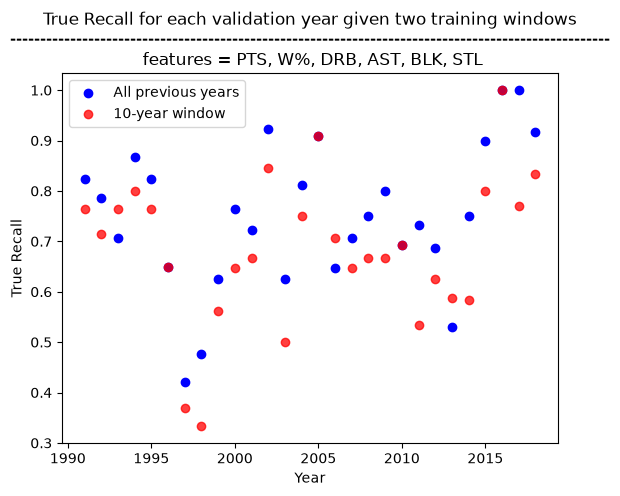

In [16]:
features = ['PTS','W%','DRB','AST','BLK','STL']
ten_yr_window = []
total_window = []
for year in range(START_YEAR+11, HOLDOUT_START):
    # test for all prior years in training data
    tr1 = df[(df['Year'] < year)]
    val = df[(df['Year'] == year)]
    
    X_tr, y_tr = tr1[features], tr1.iloc[:,-1]
    X_val, y_val = val[features], val.iloc[:,-1]
    
    model = RandomForestClassifier(random_state=29, n_jobs=-1)
    model.fit(X_tr, y_tr)

    _, recall_1 = recall_score(y_val, model.predict(X_val), average=None)
    total_window.append(recall_1)

    # test for a 10 year window
    tr2 = df[(df['Year'] < year) & (year-10 <= df['Year'])]
    val = df[(df['Year'] == year)]
    
    X_tr, y_tr = tr2[features], tr2.iloc[:,-1]
    X_val, y_val = val[features], val.iloc[:,-1]
    
    model = RandomForestClassifier(random_state=29, n_jobs=-1)
    model.fit(X_tr, y_tr)

    _, recall_1 = recall_score(y_val, model.predict(X_val), average=None)
    ten_yr_window.append(recall_1)

plt.scatter(range(START_YEAR+11, HOLDOUT_START),total_window, color='blue',label='All previous years')
plt.scatter(range(START_YEAR+11, HOLDOUT_START),ten_yr_window, color='red', label='10-year window',alpha=.75)
plt.title(f'True Recall for each validation year given two training windows\n{'-'*100}\n features = {', '.join(features)}')
plt.xlabel('Year')
plt.ylabel('True Recall')
plt.legend()
plt.show()

All previous years clearly outperforms

Check over feature sets to see if there is an optimal set

In [17]:
if RANDOM_FOREST_FEATURE_SELECTION:
    features = ['PTS','W%','DRB','AST','BLK','STL','eFG%','3P','FT']
    print(f"all features = {features}")
    for n in range(1,11):
        offset = n
        tr = df[(df['Year'] < HOLDOUT_START-offset)]
        val = df[(df['Year'] < HOLDOUT_START-(offset-1)) & (df['Year'] >= HOLDOUT_START-offset)]
        te = df[df['Year'] >= HOLDOUT_START]

        X_tr, y_tr = tr.iloc[:,:-3], tr.iloc[:,-1]
        X_val, y_val = val.iloc[:,:-3], val.iloc[:,-1]
        X_te, y_te = te.iloc[:,:-3], te.iloc[:,-1]

        # loops through every subset of at least 6 features
        # recalls maps a subset to (recall for class 0, recall for class 1)
        recalls = {}
        for size in range(6, len(features)+1):
            for subset in combinations(features, size):
                cols = list(subset)
                model = RandomForestClassifier(random_state=29, n_jobs=-1)
                model.fit(X_tr[cols], y_tr)
                recall_0, recall_1 = recall_score(y_val, model.predict(X_val[cols]), average=None)
                recalls[subset] = (recall_0, recall_1)

        # subset with the highest recall for class 1
        best = max(recalls, key=lambda s: recalls[s][1])
        print(f"validation year {HOLDOUT_START-offset}: Best subset = {best}, Recall = {recalls[best]}")
        bestfeatures = list(best)

It appears that we can use ('PTS', 'W%', 'DRB', 'AST', 'BLK', 'STL') to get good results.  There are some outliers where 3P and FT sneak in, usually replacing blocks or steals...

test whether including 3P increases of decreases performance using all years

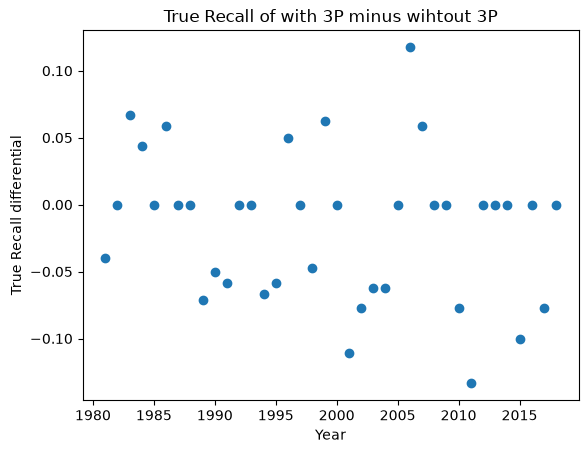

In [18]:
with_3p = []
without_3p = []
for year in range(START_YEAR+1, HOLDOUT_START):
    # dont include 3P
    features = ['PTS','W%','DRB','AST','BLK','STL']
    tr = df[(df['Year'] < year)]
    val = df[(df['Year'] == year)]
    
    X_tr, y_tr = tr[features], tr.iloc[:,-1]
    X_val, y_val = val[features], val.iloc[:,-1]
    
    model = RandomForestClassifier(random_state=29, n_jobs=-1)
    model.fit(X_tr, y_tr)

    _, recall_1 = recall_score(y_val, model.predict(X_val), average=None)
    without_3p.append(recall_1)

    # do include 3P
    features = ['PTS','W%','DRB','AST','BLK','STL','3P']
    X_tr, y_tr = tr[features], tr.iloc[:,-1]
    X_val, y_val = val[features], val.iloc[:,-1]
    
    model = RandomForestClassifier(random_state=29, n_jobs=-1)
    model.fit(X_tr, y_tr)

    _, recall_1 = recall_score(y_val, model.predict(X_val), average=None)
    with_3p.append(recall_1)

plt.scatter(range(START_YEAR+1, HOLDOUT_START),np.array(with_3p)-np.array(without_3p))
plt.title(f'True Recall of with 3P minus wihtout 3P')
plt.xlabel('Year')
plt.ylabel('True Recall differential')
plt.show()

Same for FT

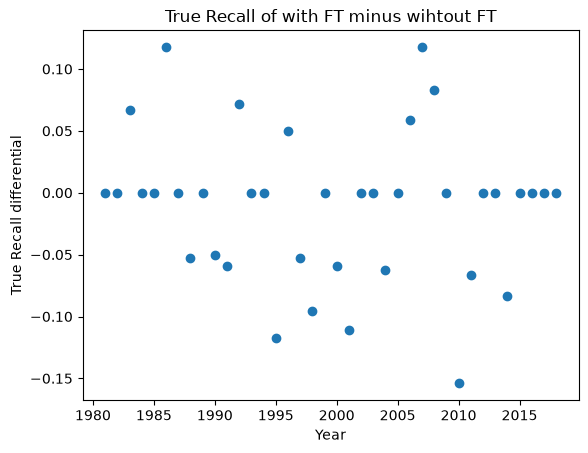

In [19]:
with_FT = []
without_FT = []
for year in range(START_YEAR+1, HOLDOUT_START):
    # dont include FT
    features = ['PTS','W%','DRB','AST','BLK','STL']
    tr = df[(df['Year'] < year)]
    val = df[(df['Year'] == year)]
    
    X_tr, y_tr = tr[features], tr.iloc[:,-1]
    X_val, y_val = val[features], val.iloc[:,-1]
    
    model = RandomForestClassifier(random_state=29, n_jobs=-1)
    model.fit(X_tr, y_tr)

    _, recall_1 = recall_score(y_val, model.predict(X_val), average=None)
    without_FT.append(recall_1)

    # do include FT
    features = ['PTS','W%','DRB','AST','BLK','STL','FT']
    X_tr, y_tr = tr[features], tr.iloc[:,-1]
    X_val, y_val = val[features], val.iloc[:,-1]
    
    model = RandomForestClassifier(random_state=29, n_jobs=-1)
    model.fit(X_tr, y_tr)

    _, recall_1 = recall_score(y_val, model.predict(X_val), average=None)
    with_FT.append(recall_1)

plt.scatter(range(START_YEAR+1, HOLDOUT_START),np.array(with_FT)-np.array(without_FT))
plt.title(f'True Recall of with FT minus wihtout FT')
plt.xlabel('Year')
plt.ylabel('True Recall differential')
plt.show()

Other than some exceptions it seems we should probably not include 3P or FT

Next we do a hyperparameter search to obtain some ideal settings for the classifier

In [23]:
features = ['PTS','W%','DRB','AST','BLK','STL']
target = 'RecievedVotes'

train = df[df.Year < HOLDOUT_START].reset_index(drop=True)
test  = df[df.Year >= HOLDOUT_START]

X_tr, y_tr = train[features], train[target]
X_te,  y_te  = test[features],  test[target]

cv = list(utils.forward_chaining_splits(train.Year, min_train_years=10))

search = RandomizedSearchCV(
    RandomForestClassifier(random_state=29, n_jobs=1),
    param_distributions={
        "n_estimators": randint(100, 1000),
        "max_depth": [None, 5, 10, 20, 30],
        "min_samples_leaf": randint(1, 10),
        "max_features": ["sqrt", "log2", 0.3, 0.5],
    },
    n_iter=50,
    cv=cv,
    scoring=make_scorer(fbeta_score, beta=3),
    n_jobs=-1,
    random_state=29,
)
search.fit(X_tr, y_tr)
print('Hyperparameter tuning complete.  Best model:')
print(search.best_params_)

model = search.best_estimator_

joblib.dump(model, str(ROOT/'misc/joblib/tuned_rf_model.joblib'), compress=3)

Hyperparameter tuning complete.  Best model:
{'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 2, 'n_estimators': 723}


['/home/fss4/workspace/fss4/erdos/basketball/fall-2026-nba-mvp-prediction/misc/joblib/tuned_rf_model.joblib']

In [24]:
for yr in range(HOLDOUT_START,END_YEAR+1):
    X_test = X_te[test.Year == yr].reset_index(drop=True)
    y_test = y_te[test.Year == yr].reset_index(drop=True)
    
    y_pred = model.predict(X_test)
    print('-'*100)
    print(yr,':')
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print(f'caught actual MVP?: {bool(df[df.Year == yr][y_pred.astype(bool)].MVP.sum())}')

----------------------------------------------------------------------------------------------------
2019 :
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       517
           1       0.53      0.83      0.65        12

    accuracy                           0.98       529
   macro avg       0.76      0.91      0.82       529
weighted avg       0.99      0.98      0.98       529

caught actual MVP?: True
----------------------------------------------------------------------------------------------------
2020 :
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       525
           1       0.48      0.73      0.58        15

    accuracy                           0.97       540
   macro avg       0.74      0.86      0.78       540
weighted avg       0.98      0.97      0.97       540

caught actual MVP?: True
----------------------------------

## Logistic Regression

In [25]:
# Accuracy report for LogisticRegression (no tuning for threshold) 
# with bestfeatures

features = ['PTS','W%','DRB','AST','BLK','STL','FT','3P','eFG%','GS%']

train = df[df['Year'] < HOLDOUT_START]
test = df[df['Year'] >= HOLDOUT_START]

X_tr, y_tr = train[features], train[target]
X_te, y_te = test[features], test[target]

cv = list(utils.forward_chaining_splits(train.Year, min_train_years=10))
print('Hyperparameter search...')
search = GridSearchCV(
    make_pipeline(
        PolynomialFeatures(degree=2), 
        StandardScaler(), 
        LogisticRegression(solver='saga',max_iter=1000, random_state=97, tol=1e-3)
    ),
    param_grid = {
        "logisticregression__C": np.logspace(-1.5, 1.5, 5),
        "logisticregression__l1_ratio": [0, 0.5, 1],
    },
    cv = cv,
    n_jobs=-1,
    scoring=make_scorer(fbeta_score, beta=2),
)
search.fit(X_tr, y_tr)
print(f'Best parameters:')
print(search.best_params_)
print('Tuning decision threshold...')
model = TunedThresholdClassifierCV(search.best_estimator_, scoring=make_scorer(fbeta_score, beta=2), cv=cv, n_jobs=-1)
model.fit(X_tr, y_tr)
joblib.dump(model, str(ROOT/"misc/joblib/tuned_lr_model.joblib"), compress=3)
print('Complete!')

Hyperparameter search...
Best parameters:
{'logisticregression__C': np.float64(5.62341325190349), 'logisticregression__l1_ratio': 0}
Tuning decision threshold...
Complete!


In [26]:
feature_names = model.estimator_[:-1].get_feature_names_out()
lr = model.estimator_.named_steps["logisticregression"]
coefs = pd.Series(lr.coef_[0], index=feature_names).sort_values()
coefs

AST FT    -0.596738
FT^2      -0.528078
DRB BLK   -0.490715
PTS BLK   -0.467436
3P        -0.415326
             ...   
W% FT      0.612311
W% BLK     0.814617
DRB^2      0.962655
W% AST     1.029046
PTS^2      1.041729
Length: 66, dtype: float64

In [27]:
for yr in range(HOLDOUT_START,END_YEAR+1):
    X_test = X_te[test.Year == yr].reset_index(drop=True)
    y_test = y_te[test.Year == yr].reset_index(drop=True)
    
    y_pred = model.predict(X_test)
    print('-'*100)
    print(yr,':')
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print(f'caught actual MVP?: {bool(df[df.Year == yr][y_pred.astype(bool)].MVP.sum())}')

----------------------------------------------------------------------------------------------------
2019 :
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       517
           1       0.48      0.92      0.63        12

    accuracy                           0.98       529
   macro avg       0.74      0.95      0.81       529
weighted avg       0.99      0.98      0.98       529

caught actual MVP?: True
----------------------------------------------------------------------------------------------------
2020 :
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       525
           1       0.52      0.93      0.67        15

    accuracy                           0.97       540
   macro avg       0.76      0.95      0.83       540
weighted avg       0.98      0.97      0.98       540

caught actual MVP?: True
----------------------------------